# Food Image Classification using a Custom CNN

This notebook documents an **image-classification** experiment using the Food-101 dataset and a **convolutional neural network (CNN)** implemented in Pytorch.

ML Approach : **Supervised Learning**  
The expected ML output: **Food Name**


The experiment is carried out in 2 stages:
1. **Balanced-subset experiment**: train using a smaller, balanced sample from each of the 101 classes. This makes the initial experiment more manageable.

2. **Full-dataset experiment**: use the complete training and validation splits to investigate whether providing more examples improves classfication performance

#### Environment Setup

In [ ]:
from google.colab import drive
import os

drive.mount('/content/drive')
PROJECT_DIR = "/content/drive/MyDrive/FoodCNN_Project"
os.makedirs(PROJECT_DIR, exist_ok=True)

Mounted at /content/drive


#### Imports

In [ ]:
from datasets import load_dataset
from tqdm.auto import tqdm
import random

import torch
import torch.nn as nn
from torch.nn.modules.pooling import MaxPool2d
from torch.nn.modules.activation import ReLU
from torch.nn.modules.batchnorm import BatchNorm2d

from torch.utils.data import Dataset, DataLoader

import matplotlib.pyplot as plt

#### Load Food-101 Dataset

The Food-101 dataset is loaded from the Hugging Face dataset repository ethz/food101.

It contains 101 food categories and is supplied with separate training and validation splits.

In [ ]:
df = load_dataset("ethz/food101")

README.md:   0%|          | 0.00/16.4k [00:00<?, ?B/s]

data/train-00000-of-00008.parquet: reconstructing file:   0%|          |  0.00B /  490MB            

data/train-00000-of-00008.parquet: downloading bytes:           |  0.00B            

data/train-00001-of-00008.parquet: reconstructing file:   0%|          |  0.00B /  464MB            

data/train-00001-of-00008.parquet: downloading bytes:           |  0.00B            

data/train-00002-of-00008.parquet: reconstructing file:   0%|          |  0.00B /  472MB            

... (15 outputs left out)

data/validation-00002-of-00003.parquet: reconstructing file:   0%|          |  0.00B /  426MB            

data/validation-00002-of-00003.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/75750 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/25250 [00:00<?, ? examples/s]

## Exploratory Data Analysis

In [ ]:
print(df)

DatasetDict({
    train: Dataset({
        features: ['image', 'label'],
        num_rows: 75750
    })
    validation: Dataset({
        features: ['image', 'label'],
        num_rows: 25250
    })
})


Inspect each split:

In [ ]:
print("Available splits:", df.keys())

for split in df.keys():

    print("\nSplit:", split)

    print("Number of rows:", len(df[split]))

    print("Features:", df[split].features)

Available splits: dict_keys(['train', 'validation'])

Split: train
Number of rows: 75750
Features: {'image': Image(mode=None, decode=True), 'label': ClassLabel(names=['apple_pie', 'baby_back_ribs', 'baklava', 'beef_carpaccio', 'beef_tartare', 'beet_salad', 'beignets', 'bibimbap', 'bread_pudding', 'breakfast_burrito', 'bruschetta', 'caesar_salad', 'cannoli', 'caprese_salad', 'carrot_cake', 'ceviche', 'cheesecake', 'cheese_plate', 'chicken_curry', 'chicken_quesadilla', 'chicken_wings', 'chocolate_cake', 'chocolate_mousse', 'churros', 'clam_chowder', 'club_sandwich', 'crab_cakes', 'creme_brulee', 'croque_madame', 'cup_cakes', 'deviled_eggs', 'donuts', 'dumplings', 'edamame', 'eggs_benedict', 'escargots', 'falafel', 'filet_mignon', 'fish_and_chips', 'foie_gras', 'french_fries', 'french_onion_soup', 'french_toast', 'fried_calamari', 'fried_rice', 'frozen_yogurt', 'garlic_bread', 'gnocchi', 'greek_salad', 'grilled_cheese_sandwich', 'grilled_salmon', 'guacamole', 'gyoza', 'hamburger', 'hot_an

Convert dataset into DataFrames

In [ ]:
import pandas as pd

train_df = df["train"].to_pandas()
validation_df = df["validation"].to_pandas()

# Combine both splits
food_df = pd.concat(
    [train_df, validation_df],
    ignore_index=True
)

In [ ]:
food_df.head()

,image,label
0,{'bytes': b'\xff\xd8\xff\xe0\x00\x10JFIF\x00\x...,6
1,{'bytes': b'\xff\xd8\xff\xe0\x00\x10JFIF\x00\x...,6
2,{'bytes': b'\xff\xd8\xff\xe0\x00\x10JFIF\x00\x...,6
3,{'bytes': b'\xff\xd8\xff\xe0\x00\x10JFIF\x00\x...,6
4,{'bytes': b'\xff\xd8\xff\xe0\x00\x10JFIF\x00\x...,6


In [ ]:
# Add food category names
# Get category names
class_names = df["train"].features["label"].names

# Convert numerical labels into category names
food_df["food_category"] = food_df["label"].apply(
    lambda x: class_names[x]
)

print(food_df.head())

                                               image  label food_category
0  {'bytes': b'\xff\xd8\xff\xe0\x00\x10JFIF\x00\x...      6      beignets
1  {'bytes': b'\xff\xd8\xff\xe0\x00\x10JFIF\x00\x...      6      beignets
2  {'bytes': b'\xff\xd8\xff\xe0\x00\x10JFIF\x00\x...      6      beignets
3  {'bytes': b'\xff\xd8\xff\xe0\x00\x10JFIF\x00\x...      6      beignets
4  {'bytes': b'\xff\xd8\xff\xe0\x00\x10JFIF\x00\x...      6      beignets


Inspect resulting DataFrame

In [ ]:
# Dataset shape
food_df.shape

(101000, 3)

In [ ]:
# Column names
food_df.columns

Index(['image', 'label', 'food_category'], dtype='object')

In [ ]:
# Dataset information
food_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 101000 entries, 0 to 100999
Data columns (total 3 columns):
 #   Column         Non-Null Count   Dtype 
---  ------         --------------   ----- 
 0   image          101000 non-null  object
 1   label          101000 non-null  int64 
 2   food_category  101000 non-null  object
dtypes: int64(1), object(2)
memory usage: 2.3+ MB


In [ ]:
# Missing values
food_df.isnull().sum()

,0
image,0
label,0
food_category,0


In [ ]:
# Statistical summary
food_df[["food_category"]].describe()

,food_category
count,101000
unique,101
top,beignets
freq,1000


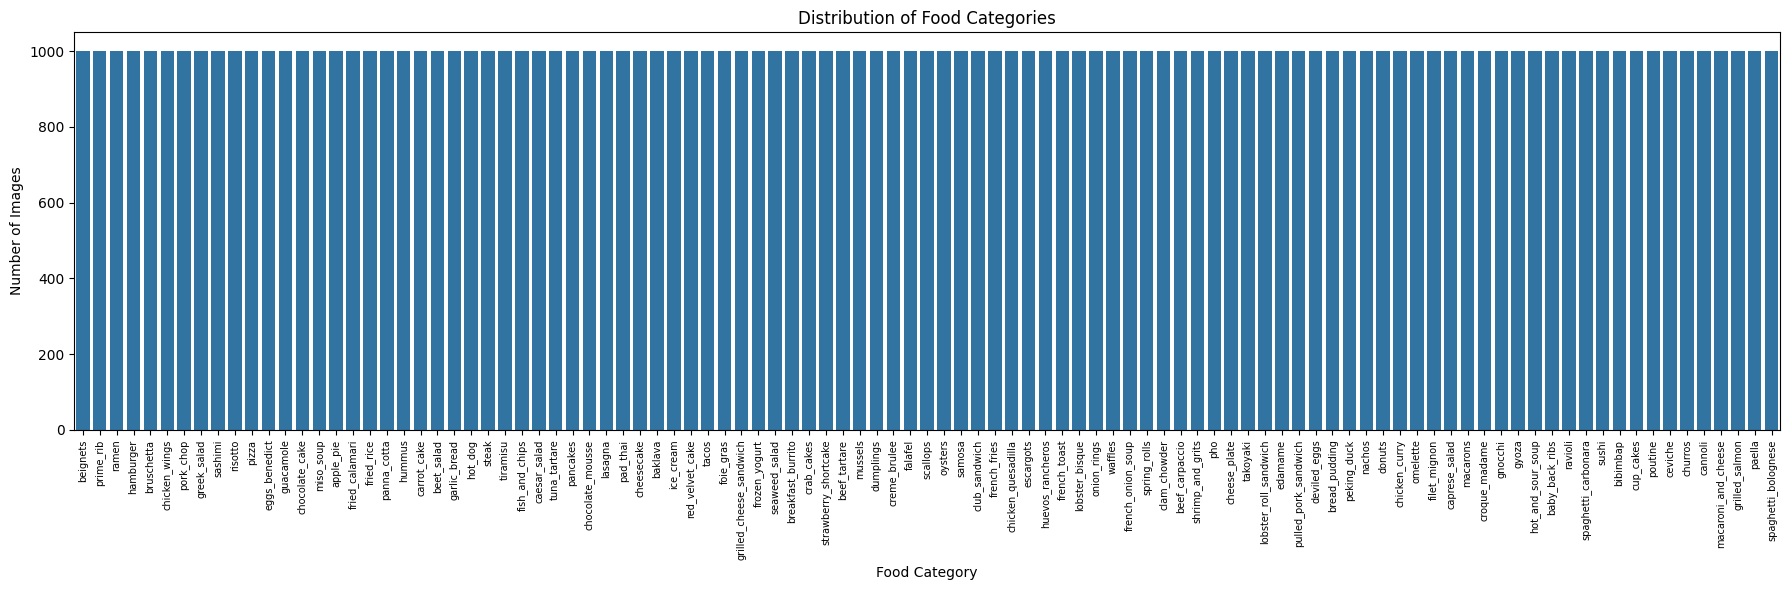

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Category Distribution
category_counts = food_df["food_category"].value_counts()

plt.figure(figsize=(18, 6))

sns.barplot(
    x=category_counts.index,
    y=category_counts.values
)

plt.title("Distribution of Food Categories")
plt.xlabel("Food Category")
plt.ylabel("Number of Images")

plt.xticks(rotation=90, fontsize=7)

plt.tight_layout()
plt.show()

The categories are equal all across. The dataset is balanced.

In [ ]:
from PIL import Image
from io import BytesIO

image_dimensions = []

for image_data in food_df["image"]:
  if image_data["bytes"] is not None:
    image = Image.open(BytesIO(image_data["bytes"]))

  else:
    image = Image.open(image_data["path"])

width, height = image.size

image_dimensions.append({
    "width": width,
    "height": height
})

dimensions_df = pd.DataFrame(image_dimensions)

In [ ]:
# Check dimension consistency
print("Unique dimensions:", len(
    dimensions_df.drop_duplicates()
))

print("\nMost common dimensions:")

print(
    dimensions_df.value_counts(["width", "height"]).head(10)
)

Unique dimensions: 1

Most common dimensions:
width  height
512    512       1
Name: count, dtype: int64


All images have identical dimensions (512 x 512)

## Experiment 1 -  Training on a Balanced Subset

In [ ]:
def get_balanced_subset(dataset, images_per_class, seed=42):
  random.seed(seed)

  selected_indices = []
  class_indices = {}

  # Get all labels without accessing the images
  labels = dataset["label"]

  # Group dataset indices by class
  for i, label in enumerate(labels):
    if label not in class_indices:
      class_indices[label] = []

    class_indices[label].append(i)

  # Randomly select images from each class
  for label in range(101):
    indices = class_indices[label]

    selected = random.sample(
        indices,
        images_per_class
    )

    selected_indices.extend(selected)

  return dataset.select(selected_indices)


In [ ]:
# 100 images per class for training
# 25 images per class for validation
train_data = get_balanced_subset(df["train"], 100)
val_data = get_balanced_subset(df["validation"], 25)

In [ ]:
print("Training images: ", len(train_data))
print("Validation images: ", len(val_data))

Training images:  10100
Validation images:  2525


#### Convert Image to Python Tensor

In [ ]:
from torchvision import transforms

train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(), # introduce variations in food positioning
    transforms.RandomRotation(15), # variations in orientation
    transforms.ToTensor()
])

val_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor()
])

In [ ]:
image = train_data[0]["image"].convert("RGB")

In [ ]:
image_tensor = train_transform(image)

print(image_tensor.shape)
print(image_tensor.dtype)

torch.Size([3, 224, 224])
torch.float32


#### Convert dataset into Pytorch Dataset

In [ ]:
class FoodDataset(Dataset):
  def __init__(self, dataset, transform=None):
    self.dataset = dataset
    self.transform = transform

  def __len__(self):
    return len(self.dataset)

  def __getitem__(self, index):
    image = self.dataset[index]["image"].convert("RGB")
    label = self.dataset[index]["label"]

    if self.transform:
      image = self.transform(image)

    return image, torch.tensor(label, dtype=torch.long)

In [ ]:
# Training and validation datasets
train_dataset = FoodDataset(
    train_data,
    transform=train_transform
)

val_dataset = FoodDataset(
    val_data,
    transform=val_transform
)

In [ ]:
# Create data loaders
train_loader = DataLoader(
    train_dataset,
    batch_size=32,
    shuffle=True,
    num_workers=0
)

test_loader = DataLoader(
    val_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=0
)

A `DataLoader` groups examples into batches of 32. Training batches are shuffled so that the model does not see examples in the same order every epoch. Validation batches are not shuffled.

In [ ]:
# Test Data Loader
images, labels = next(iter(train_loader))

print(images.shape)
print(labels.shape)

torch.Size([32, 3, 224, 224])
torch.Size([32])


Visualize a sample Image

In [ ]:
# Get actual dish names
class_names = train_data.features["label"].names

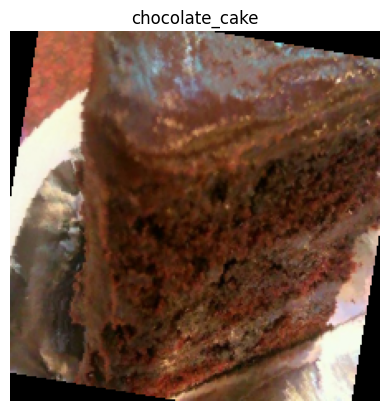

In [ ]:
plt.imshow(images[0].permute(1, 2, 0))
plt.title(class_names[labels[0].item()])
plt.axis("off")
plt.show()

### Design the custom CNN architecture

Each convolutional block contains:
- A 3 x 3 convolution to learn image features.
- Batch normalization to normalize intermediate activations.
- ReLU to introduce non-linearity
- 2 x 2 max pooling to reduce the spatial dimensions.

**Actual architecture**

- **Input Image** -> 3 x 244 x 244
- **Convolution Block 1**
  - Conv 3 -> 32 + BatchNorm + ReLU + MaxPool
  - 32 x 112 x 112
- **Convolution Block 2**
  - Conv 32 -> 64 + BatchNorm + ReLU + MaxPool
  - 64 x 56 x 56
- **Convolution Block 3**
  - Conv 64 -> 128 + BatchNorm + ReLU + MaxPool
  - 256 x 28 x 28
- **Convolution Block 4**
  - Conv 128 -> 256 + BatchNorm + ReLU + MaxPool
  - 256 x 14 x 14
- **Adaptive Average Pooling**
  - 256 x 1 x 1
- **Flatten + Dropout**
- **Fully connected Layer**
  - 256 -> 101 (food classes)

All convolutional layers use 3 x 3 filters with a stride of 1 and padding of 1, while all max-pooling layers use 2 x 2 filters with a stride of 2.

### Implement the CNN

In [ ]:
class FoodCNN(nn.Module):
  def __init__(self, num_classes=101):
    super().__init__()

    # Convolutional blocks
    self.conv_layers = nn.Sequential(
        # Block 1
        nn.Conv2d(3, 32, kernel_size=3, padding=1),
        nn.BatchNorm2d(32),
        nn.ReLU(),
        nn.MaxPool2d(2),

        # Block 2
        nn.Conv2d(32, 64, kernel_size=3, padding=1),
        nn.BatchNorm2d(64),
        nn.ReLU(),
        nn.MaxPool2d(2),

        # Block 3
        nn.Conv2d(64, 128, kernel_size=3, padding=1),
        nn.BatchNorm2d(128),
        nn.ReLU(),
        nn.MaxPool2d(2),

        # Block 4
        nn.Conv2d(128, 256, kernel_size=3, padding=1),
        nn.BatchNorm2d(256),
        nn.ReLU(),
        nn.MaxPool2d(2)
    )

    # Classification layers
    self.classifier = nn.Sequential(
        nn.AdaptiveAvgPool2d((1, 1,)),
        # This averages each feature map into a single value.
        # This gives us just 256 values to pass into the final classification layer,
        # reducing the number of parameters significantly
        nn.Flatten(),
        nn.Dropout(0.5), # randomly disables some neurons during training to help reduce overfitting
        nn.Linear(256, num_classes)
    )

  def forward(self, x):
    x = self.conv_layers(x)
    x = self.classifier(x)
    return x

### Configure the model and learning process

In [ ]:
# Check whether you have access to GPU
# Training on GPU is faster
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

model = FoodCNN(num_classes=101).to(device)

print(device)

cuda


In [ ]:
# Loss function
criterion = nn.CrossEntropyLoss()

In [ ]:
# Optimizer - Adam
# Adam adjusts the model's weights using the gradients calculated
# during backpropagation
optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001
)

### Training Procedure

In [ ]:
def train_model(model, train_loader, criterion, optimizer, device):
  model.train() # Training mode

  running_loss = 0.0
  correct = 0
  total = 0

  progress_bar = tqdm(train_loader, desc="Training", leave=True)

  for images, labels in progress_bar:
    images = images.to(device)
    labels = labels.to(device)

    # Clear previous gradients from previous batch
    optimizer.zero_grad()

    # Forward pass
    outputs = model(images)

    # Calculate loss
    loss = criterion(outputs, labels)

    # Backpropagation
    loss.backward()

    # Update weights
    optimizer.step()

    # Track loss
    running_loss += loss.item() * images.size(0)

    # Calculate accuracy
    _, predicted = torch.max(outputs, 1)

    total += labels.size(0)
    correct += (predicted == labels).sum().item()

    # Update progress bar
    progress_bar.set_postfix({
        "Loss": f"{running_loss / total:.4f}",
        "Accuracy": f"{100 * correct / total:.2f}"
    })

  epoch_loss = running_loss / total
  epoch_accuracy = 100 * correct / total

  return epoch_loss, epoch_accuracy

### Validation Procedure

In [ ]:
def evaluate_model(model, data_loader, criterion, device):
  model.eval()

  running_loss = 0.0
  correct = 0
  total = 0

  progress_bar = tqdm(data_loader, desc="Validation", leave=True)

  with torch.no_grad():

    for images, labels in progress_bar:

      images = images.to(device)
      labels = labels.to(device)

      # Forward pass
      outputs = model(images)

      # Calculate loss
      loss = criterion(outputs, labels)

      running_loss += loss.item() * images.size(0)

      # Calculate accuracy
      _, predicted = torch.max(outputs, 1)

      total += labels.size(0)
      correct += (predicted == labels).sum().item()

      progress_bar.set_postfix({
          "Loss": f"{running_loss / total:.4f}",
          "Accuracy": f"{100 * correct / total:.2f}%"
      })

  epoch_loss = running_loss / total
  epoch_accuracy = 100 * correct / total

  return epoch_loss, epoch_accuracy

### Train Model on the balanced subset

The model is trained over multiple epochs. At the end of each epoch, training and validation loss and accuracy are recorded.

A `ReduceLROnPlateau` scheduler reduces the learning rate when validation loss stops improving.

In [ ]:
epochs = 70 # will change

train_losses = []
train_accuracies = []

val_losses = []
val_accuracies = []

best_val_acc = 0.0

In [ ]:
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode = "min",
    factor = 0.5,
    patience = 3
)

In [ ]:
start_epoch = 20

epochs = 70

for epoch in range(start_epoch, epochs):

  print(f"\nEpoch [{epoch+1}/{epochs}]")

  train_loss, train_acc = train_model(
      model,
      train_loader,
      criterion,
      optimizer,
      device
  )

  val_loss, val_acc = evaluate_model(
      model,
      test_loader,
      criterion,
      device
  )

  train_losses.append(train_loss)
  train_accuracies.append(train_acc)

  val_losses.append(val_loss)
  val_accuracies.append(val_acc)

  print(f"Train Loss: {train_loss:.4f} | Train Accuracy: {train_acc:.2f}%")
  print(f"Val Loss: {val_loss:.4f} | Val Accuracy: {val_acc:.2f}")

  # Update learning rate scheduler
  scheduler.step(val_loss)

  # Save the best model
  if val_acc > best_val_acc:
    best_val_acc = val_acc

    torch.save(
        model.state_dict(),
        f"{PROJECT_DIR}/best_food_cnn.pth"
    )

    print("Best model saved!")

  # Save complete checkpoint after every epoch
  checkpoint = {
        "epoch": epoch + 1,
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "scheduler_state_dict": scheduler.state_dict(),
        "best_val_acc": best_val_acc,
        "train_losses": train_losses,
        "train_accuracies": train_accuracies,
        "val_losses": val_losses,
        "val_accuracies": val_accuracies
  }

  torch.save(
      checkpoint,
      f"{PROJECT_DIR}/latest_checkpoint.pth"
  )

  print("Latest checkpoint saved!")
  print("-" * 50)


Epoch [21/70]


NameError: name 'train_loader' is not defined

In [ ]:
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode = "min",
    factor = 0.5,
    patience = 3
)

In [ ]:
def visualize_subset():
  plt.figure(figsize=(12, 5))

  plt.subplot(1, 2, 1)
  plt.plot(train_losses, label="Training Loss")
  plt.plot(val_losses, label="Validation Loss")
  plt.xlabel("Epoch")
  plt.ylabel("Loss")
  plt.title("Training vs Validation Loss")
  plt.legend()

  plt.subplot(1, 2, 2)
  plt.plot(train_accuracies, label="Training Accuracy")
  plt.plot(val_accuracies, label="Validation Accuracy")
  plt.xlabel("Epoch")
  plt.ylabel("Accuracy (%)")
  plt.title("Training vs Validation Accuracy")
  plt.legend()

  plt.tight_layout()
  plt.show()

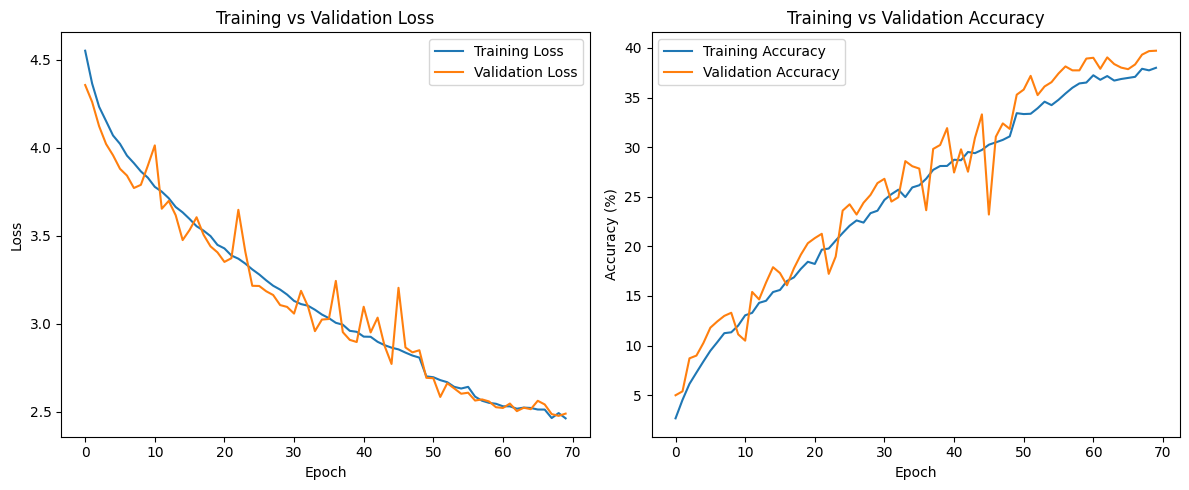

In [ ]:
visualize_subset()

In [ ]:
# best_val_acc=39.722772277227726

### Balanced-subset experiment result

The recorded best validation accuracy for this experiment is 39.72%

This is the baseline result for the custom CNN trained on 10,100 training images and evaluated on 2,525 validation images.

The next section investigates whether training with the full dataset improves performance.

## Experiment 2 - Training on the Full Food-101 Dataset

**Motivation**

The first experiment used only a small sample of each class. The next experiment increases the amount of training data by using the complete training & validation splits provided by Food-101

In [ ]:
train_data = df["train"]
val_data = df["validation"]

print("Training images: ", len(train_data))
print("Validation images: ", len(val_data))

Training images:  75750
Validation images:  25250


In [ ]:
train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(), # introduce variations in food positioning
    transforms.RandomRotation(15), # variations in orientation
    transforms.ToTensor()
])

val_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor()
])

In [ ]:
train_dataset = FoodDataset(
    train_data,
    transform=train_transform
)

val_dataset = FoodDataset(
    val_data,
    transform=val_transform
)

In [ ]:
# Create Data Loaders
batch_size = 32

train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True,
    num_workers=0
)

val_loader = DataLoader(
    val_dataset,
    batch_size=batch_size,
    shuffle=False,
    num_workers=0
)

This gives us approximately:
- 2368 training batches per epoch
- 790 validation batches per epoch

In [ ]:
# Load our best model (from the subset experience)
PROJECT_DIR = "/content/drive/MyDrive/FoodCNN_Project"

MODEL_PATH = f"{PROJECT_DIR}/best_food_cnn.pth"



model.load_state_dict(
    torch.load(MODEL_PATH, map_location=device)
)

model.eval()

FoodCNN(
  (conv_layers): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (5): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (6): ReLU()
    (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (8): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (9): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (10): ReLU()
    (11): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (12): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (13): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True

In [ ]:
# Prepare for fine tuning
criterion = nn.CrossEntropyLoss()

In [ ]:
optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.0001 # Adam learning rate is reduced from 0.001 to 0.0001
)

In [ ]:
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.5,
    patience=3
)

In [ ]:
full_train_losses = []
full_val_losses = []

full_train_accuracies = []
full_val_accuracies = []

best_val_acc = 0.0

In [ ]:
BEST_MODEL_PATH = f"{PROJECT_DIR}/best_food_cnn_full.pth"
LATEST_CHECKPOINT_PATH = f"{PROJECT_DIR}/latest_full_checkpoint.pth"

In [ ]:
# start_epoch = 0

epochs = 40

for epoch in range(start_epoch, epochs):

    print(f"\nEpoch {epoch + 1}/{epochs}")

    train_loss, train_acc = train_model(
        model,
        train_loader,
        criterion,
        optimizer,
        device
    )

    val_loss, val_acc = evaluate_model(
        model,
        val_loader,
        criterion,
        device
    )

    scheduler.step(val_loss)

    full_train_losses.append(train_loss)
    full_val_losses.append(val_loss)

    full_train_accuracies.append(train_acc)
    full_val_accuracies.append(val_acc)

    if val_acc > best_val_acc:
        best_val_acc = val_acc

        torch.save(
            model.state_dict(),
            BEST_MODEL_PATH
        )

        print("Best model saved!")

    # Save complete checkpoint after every epoch
    checkpoint = {
        "epoch": epoch + 1,
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "scheduler_state_dict": scheduler.state_dict(),
        "best_val_acc": best_val_acc,
        "train_losses": full_train_losses,
        "val_losses": full_val_losses,
        "train_accuracies": full_train_accuracies,
        "val_accuracies": full_val_accuracies
    }

    torch.save(
        checkpoint,
        LATEST_CHECKPOINT_PATH
    )

    print(f"Training Accuracy: {train_acc:.2f}%")
    print(f"Validation Accuracy: {val_acc:.2f}%")
    print(f"Training Loss: {train_loss:.4f}")
    print(f"Validation Loss: {val_loss:.4f}")

    print("Latest checkpoint saved!")
    print("-" * 50)


Epoch 33/40


Training:   0%|          | 0/2368 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/PIL/TiffImagePlugin.py:950: UserWarning: Truncated File Read
  warnings.warn(str(msg))


Validation:   0%|          | 0/790 [00:00<?, ?it/s]

Best model saved!
Training Accuracy: 37.17%
Validation Accuracy: 48.42%
Training Loss: 2.5694
Validation Loss: 2.1178
Latest checkpoint saved!
--------------------------------------------------

Epoch 34/40


Training:   0%|          | 0/2368 [00:00<?, ?it/s]

... (11 outputs left out)

Training:   0%|          | 0/2368 [00:00<?, ?it/s]

Validation:   0%|          | 0/790 [00:00<?, ?it/s]

Training Accuracy: 37.90%
Validation Accuracy: 48.82%
Training Loss: 2.5430
Validation Loss: 2.1096
Latest checkpoint saved!
--------------------------------------------------

Epoch 39/40


Training:   0%|          | 0/2368 [00:00<?, ?it/s]

In [ ]:
best_val_acc

48.03168316831683

**Result after the first full-dataset training stage**

The recorded best validation accuracy after this stage is approximately 48.03%

This is higher than the 39.72% obtained in the balanced subset experiment. The result suggests that the additional training examples helped the custom CNN learn more useful features.

#### Resume Training from Latest checkpoint

In [ ]:
LATEST_CHECKPOINT_PATH = f"{PROJECT_DIR}/latest_full_checkpoint.pth"

checkpoint = torch.load(
    LATEST_CHECKPOINT_PATH,
    map_location=device,
    weights_only=False
)

model.load_state_dict(checkpoint["model_state_dict"])
optimizer.load_state_dict(checkpoint["optimizer_state_dict"])
scheduler.load_state_dict(checkpoint["scheduler_state_dict"])

start_epoch = checkpoint["epoch"]
best_val_acc = checkpoint["best_val_acc"]

full_train_losses = checkpoint["train_losses"]
full_val_losses = checkpoint["val_losses"]
full_train_accuracies = checkpoint["train_accuracies"]
full_val_accuracies = checkpoint["val_accuracies"]

In [ ]:
start_epoch

40

In [ ]:
# start_epoch = 40

epochs = 65

for epoch in range(60, epochs):

    print(f"\nEpoch {epoch + 1}/{epochs}")

    train_loss, train_acc = train_model(
        model,
        train_loader,
        criterion,
        optimizer,
        device
    )

    val_loss, val_acc = evaluate_model(
        model,
        val_loader,
        criterion,
        device
    )

    scheduler.step(val_loss)

    full_train_losses.append(train_loss)
    full_val_losses.append(val_loss)

    full_train_accuracies.append(train_acc)
    full_val_accuracies.append(val_acc)

    if val_acc > best_val_acc:
        best_val_acc = val_acc

        torch.save(
            model.state_dict(),
            BEST_MODEL_PATH
        )

        print("Best model saved!")

    # Save complete checkpoint after every epoch
    checkpoint = {
        "epoch": epoch + 1,
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "scheduler_state_dict": scheduler.state_dict(),
        "best_val_acc": best_val_acc,
        "train_losses": full_train_losses,
        "val_losses": full_val_losses,
        "train_accuracies": full_train_accuracies,
        "val_accuracies": full_val_accuracies
    }

    torch.save(
        checkpoint,
        LATEST_CHECKPOINT_PATH
    )

    print(f"Training Accuracy: {train_acc:.2f}%")
    print(f"Validation Accuracy: {val_acc:.2f}%")
    print(f"Training Loss: {train_loss:.4f}")
    print(f"Validation Loss: {val_loss:.4f}")

    print("Latest checkpoint saved!")
    print("-" * 50)


Epoch 61/65


Training:   0%|          | 0/2368 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/PIL/TiffImagePlugin.py:950: UserWarning: Truncated File Read
  warnings.warn(str(msg))


Validation:   0%|          | 0/790 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/PIL/TiffImagePlugin.py:950: UserWarning: Truncated File Read
  warnings.warn(str(msg))


Best model saved!
Training Accuracy: 39.98%
Validation Accuracy: 51.47%
Training Loss: 2.4473
Validation Loss: 1.9843
Latest checkpoint saved!
--------------------------------------------------

Epoch 62/65


... (9 outputs left out)

Best model saved!
Training Accuracy: 40.10%
Validation Accuracy: 51.85%
Training Loss: 2.4355
Validation Loss: 1.9720
Latest checkpoint saved!
--------------------------------------------------

Epoch 65/65


Training:   0%|          | 0/2368 [00:00<?, ?it/s]

Validation:   0%|          | 0/790 [00:00<?, ?it/s]

Training Accuracy: 39.88%
Validation Accuracy: 51.40%
Training Loss: 2.4397
Validation Loss: 1.9925
Latest checkpoint saved!
--------------------------------------------------


### Results and discussion

The best recorded validation accuracy for the full-dataset experiment is 51.85%

| Experiment | Training data | Validation data | Best recorded validation accuracy |
| ---------- | ------------- | --------------- | ---------------------------- |
| Balanced subset | 10,100 images | 2,525 images | 39.72% |
| Full dataset | 75,750 images | 25,250 images | 51.85% |


**Interpreting the result**

The improvement (12.13 percentage points) indicates that the mode benefited from having access to more training examples.

However, a validation accuracy of 51.85% also means that the model still makes incorrect predictions on a substantial proportion of validation images

**Limitations to Consider**

- **Visual similarity between food classes**: some dishes can look similar, making classification difficult
- **Custom architecture**: The network is relatively simple with deeper CNN architectures commonly used for large-scale image classification

### Visualize training & validation performance

In [ ]:
def visualize_subset():
  plt.figure(figsize=(12, 5))

  plt.subplot(1, 2, 1)
  plt.plot(full_train_losses, label="Training Loss")
  plt.plot(full_val_losses, label="Validation Loss")
  plt.xlabel("Epoch")
  plt.ylabel("Loss")
  plt.title("Training vs Validation Loss")
  plt.legend()

  plt.subplot(1, 2, 2)
  plt.plot(full_train_accuracies, label="Training Accuracy")
  plt.plot(full_val_accuracies, label="Validation Accuracy")
  plt.xlabel("Epoch")
  plt.ylabel("Accuracy (%)")
  plt.title("Training vs Validation Accuracy")
  plt.legend()

  plt.tight_layout()
  plt.show()

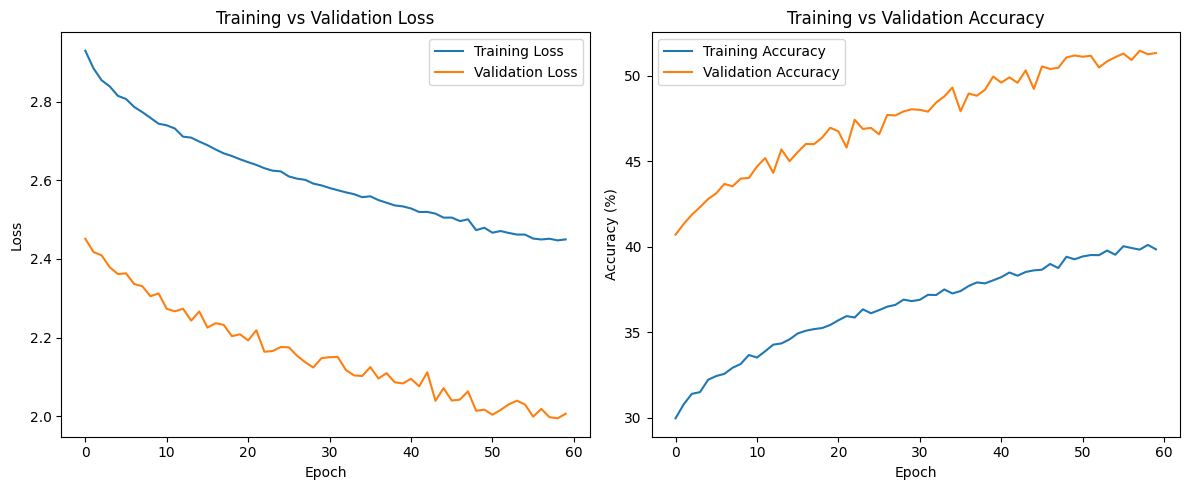

In [ ]:
visualize_subset()

### Confusion Matrix

In [ ]:
import numpy as np

In [ ]:
all_predictions = []
all_labels = []

model.eval()

FoodCNN(
  (conv_layers): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (5): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (6): ReLU()
    (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (8): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (9): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (10): ReLU()
    (11): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (12): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (13): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True

In [ ]:
with torch.inference_mode():
  for images, labels in val_loader:
    images = images.to(device)

    outputs = model(images)

    # Get the class with the highest predicted score
    predictions = torch.argmax(outputs, dim=1)

    all_predictions.extend(predictions.cpu().numpy())
    all_labels.extend(labels.numpy())

all_predictions = np.array(all_predictions)
all_labels = np.array(all_labels)

print("Predictions collected:", len(all_predictions))
print("Actual labels collected:", len(all_labels))

/usr/local/lib/python3.13/dist-packages/PIL/TiffImagePlugin.py:950: UserWarning: Truncated File Read
  warnings.warn(str(msg))


Predictions collected: 25314
Actual labels collected: 25314


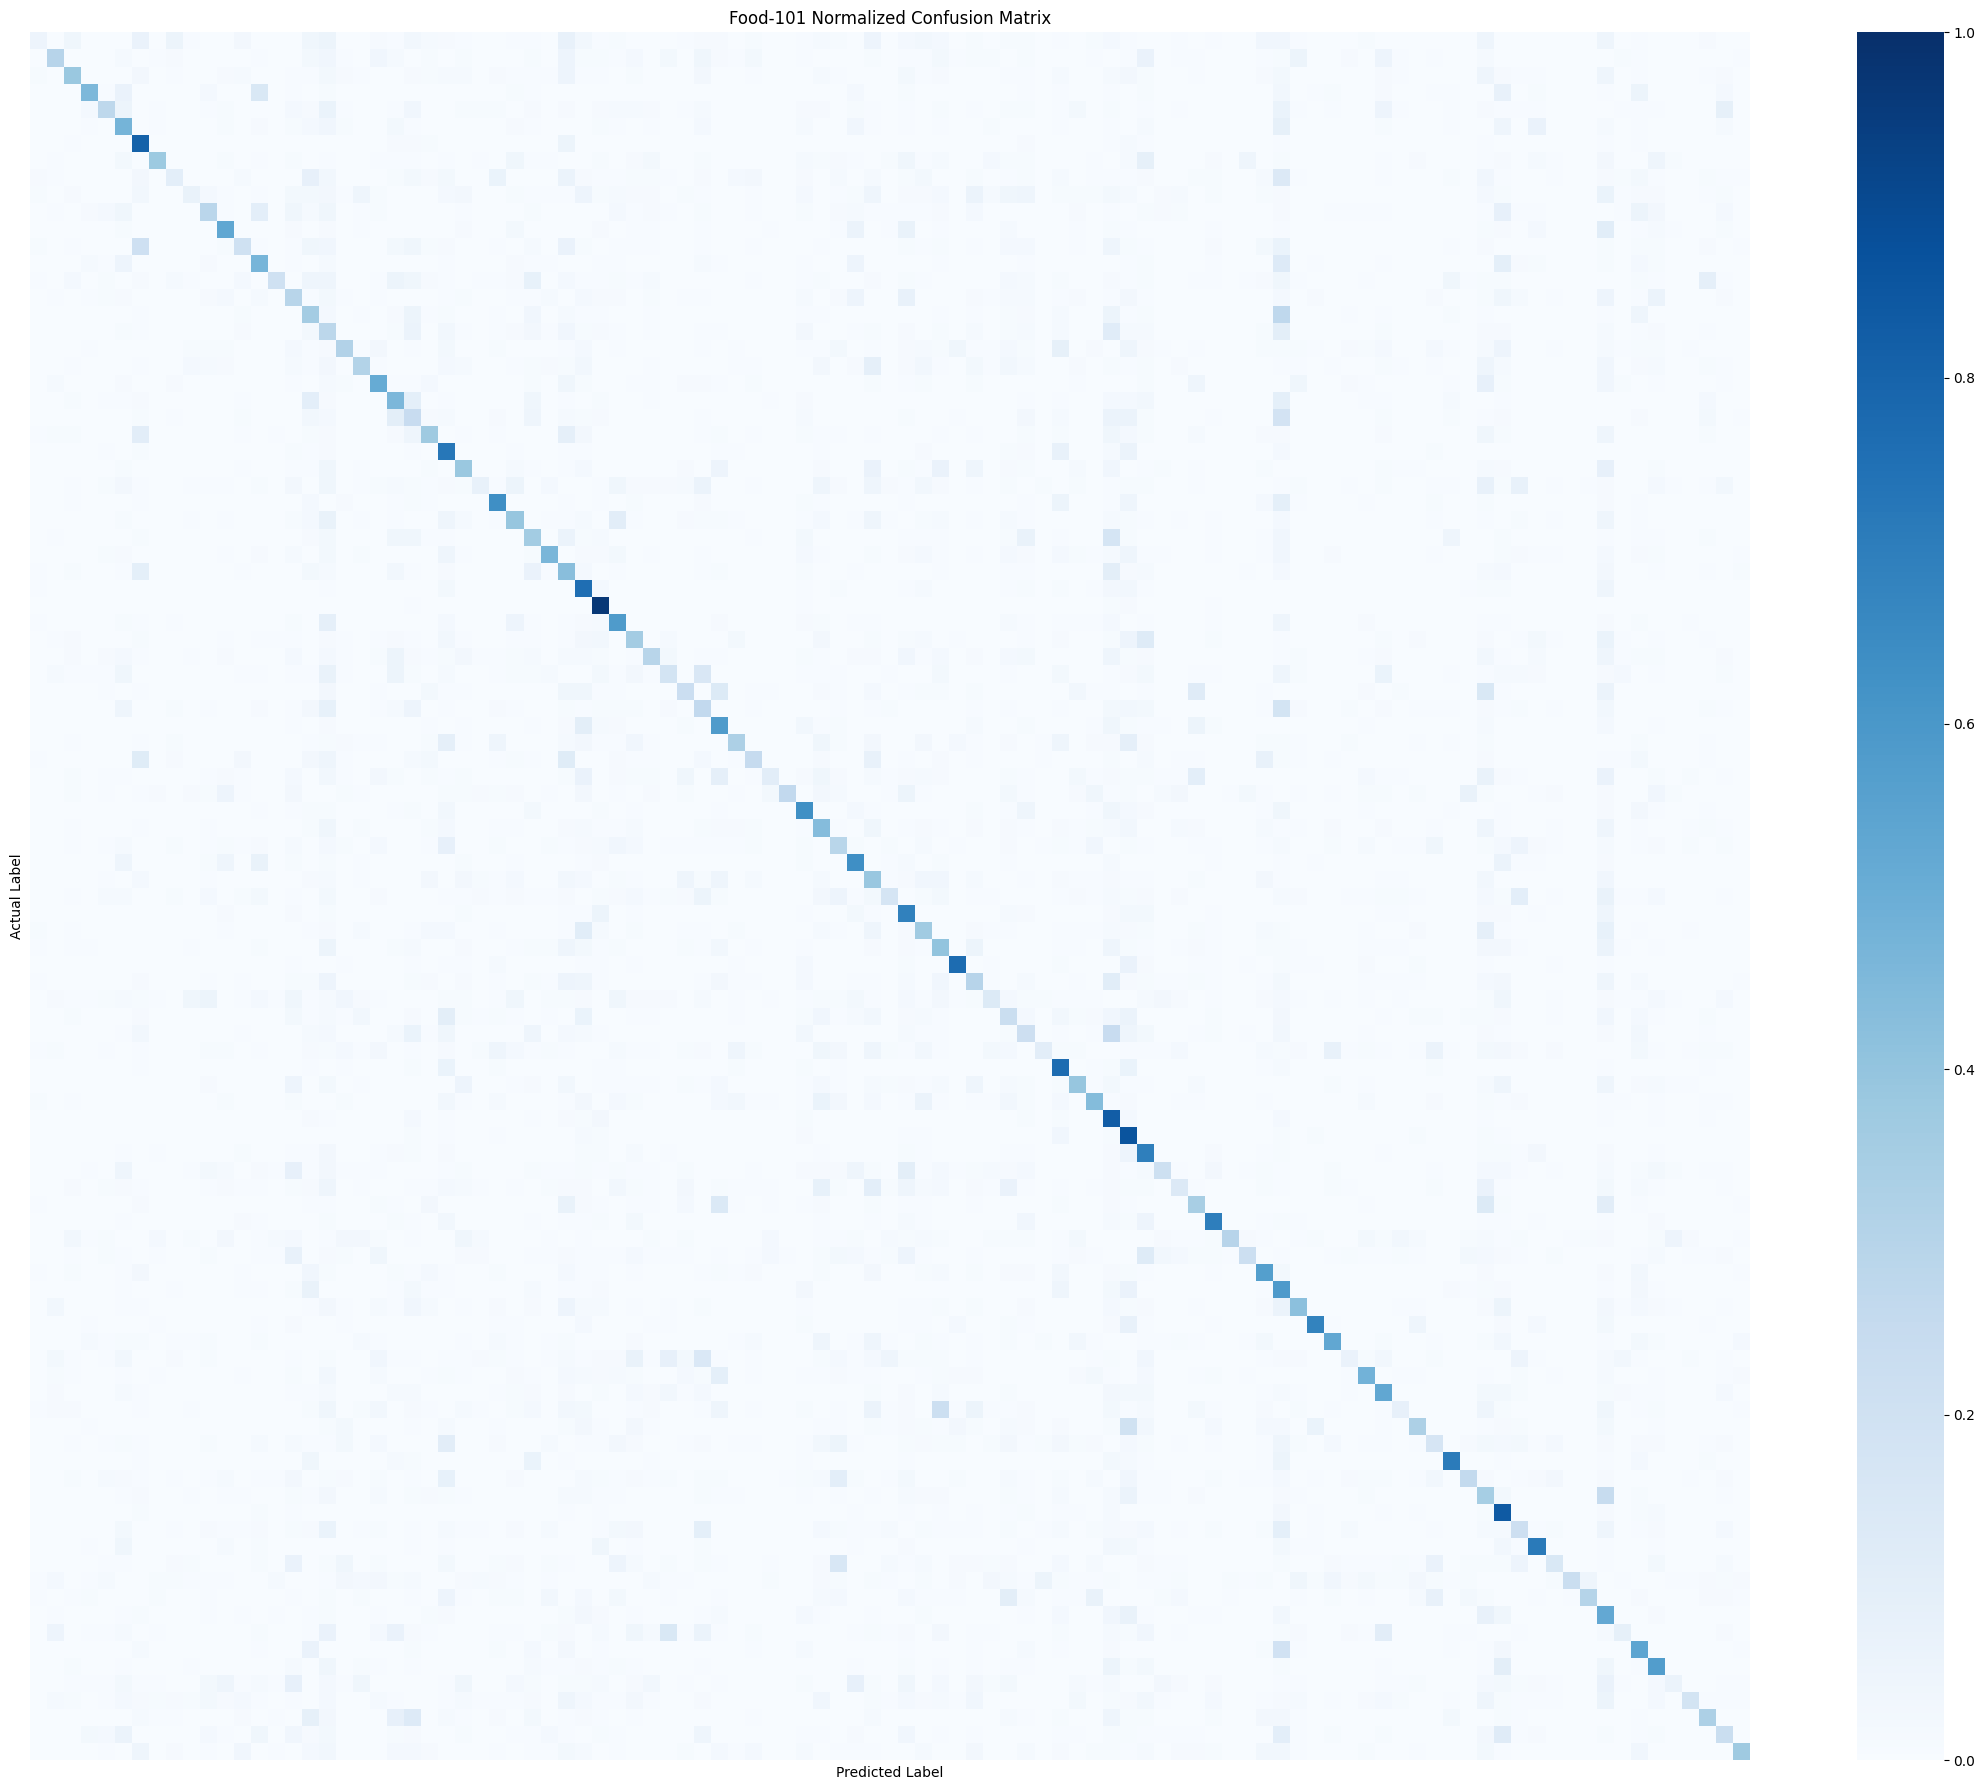

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Get Food-101 class names
class_names = df["train"].features["label"].names

# Generate confusion matrix
cm = confusion_matrix(
    all_labels,
    all_predictions,
    labels = range(101)
)


# Normalize each row to show percentages
cm_normalized = cm.astype('float') / cm.sum(axis=1, keepdims=True)

# Plot confusion matrix
plt.figure(figsize=(22, 18))

sns.heatmap(
    cm_normalized,
    cmap="Blues",
    xticklabels=False,
    yticklabels=False,
    vmin=0,
    vmax=1
)

plt.title("Food-101 Normalized Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")

plt.tight_layout()
plt.show()

The diagonal line represents the correct predictions, with darker cells showing higher accuracy levels for each image classified.

The confusion matrix above shows a visible diagonal, which suggests that our model is learning to distinguish between the food categories.

In [ ]:
from sklearn.metrics import classification_report

report = classification_report(
    all_labels,
    all_predictions,
    target_names=class_names,
    digits=4,
    zero_division=0
)

print(report)

                         precision    recall  f1-score   support

              apple_pie     0.3250    0.0520    0.0897       250
         baby_back_ribs     0.5319    0.3000    0.3836       250
                baklava     0.5486    0.3840    0.4518       250
         beef_carpaccio     0.7500    0.4560    0.5672       250
           beef_tartare     0.5349    0.2760    0.3641       250
             beet_salad     0.3371    0.4760    0.3947       250
               beignets     0.4847    0.8057    0.6053       314
               bibimbap     0.7899    0.3760    0.5095       250
          bread_pudding     0.3049    0.1000    0.1506       250
      breakfast_burrito     0.3214    0.0720    0.1176       250
             bruschetta     0.4235    0.2880    0.3429       250
           caesar_salad     0.5542    0.5320    0.5429       250
                cannoli     0.3953    0.2040    0.2691       250
          caprese_salad     0.4199    0.4720    0.4444       250
            carrot_cake 

The `overall model accuracy` was 39.28% across the training set.

The `precision` is 45.52%, showing what it predicted was actually
 what the image was most times.

The overall `recall` is 39.18%, showing how often it gets the prediction right.

The `weighted F1-score` is 38.14% and the `macro F1-score` is 38.08%, indicating that the model has a relatively low balance between precision and recall across the 101 food categories.

# Final Comparison

| Architecture | Total Number of Epochs |Best Validation Accuracy |
| ------------ | ---------------------- | ----------------------- |
| Custom CNN (Balanced Subset) | 70 | 39.72% | - | - | - |
| Custom CNN (Whole Dataset) | 65 | 51.85% |
| Efficient NetB0 (with pretrained weights) | 20 | 86.0% |